### Generative AI applications Project

##### Name: Sayed Saidoo

##### Dataset: Cornell Movie-Dialogs

##### Project Overview

This project applies generative artificial intelligence techniques to the Cornell Movie-Dialogs Corpus to develop a decoder-only Transformer capable of generating coherent movies tyle dialogue through autoregressive language modeling. The corpus contains human authored conversational exchanges extracted from film scripts and provides a rich source of dialogue patterns, character interactions, and natural language structure suitable for conversational text generation.

The primary objective of this project is to design, train, and evaluate a GPT-style Transformer model using PyTorch while following a complete generative AI workflow. The analysis includes raw data reconstruction, conversational preprocessing, vocabulary exploration, custom tokenizer development, tokenization experiments, model implementation, training, evaluation, and qualitative assessment of generated text outputs.

This study places greater emphasis on improving generative quality through data-centric decisions, tokenizer optimization, training efficiency, and systematic evaluation.

The study focuses on the following research question:

*Can a custom-tokenized decoder-only Transformer learn richer conversational patterns from human-authored movie dialogue and generate coherent, contextually appropriate dialogue while remaining computationally efficient on modest GPU resources?*

To address this question, a GPT-style Transformer will be trained on the Cornell Movie-Dialogs Corpus using a custom domain-specific tokenizer and explicit conversational boundary markers. The resulting model will be evaluated using both quantitative language modeling metrics and qualitative text generation examples.

#### Import Core Dependencies

In [1]:
import torch
import pandas as pd
import numpy as np
from datasets import load_dataset
from transformers import GPT2TokenizerFast
from transformers import PreTrainedTokenizerFast
from typing import Any
from pathlib import Path
from collections import Counter
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.nn.functional as F
import math
from tqdm.auto import tqdm
import ast
import statistics as stats
import re
from tokenizers import Tokenizer, trainers, pre_tokenizers, Regex
from tokenizers.models import BPE


# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:

# Colab configuration not required if running locally
# %cd /content/generative-ai-applications-project/notebooks

# Verify data folders are visible
#!ls -la

/content/generative-ai-applications-project/notebooks
total 164
drwxr-xr-x 2 root root   4096 Oct 11 18:32 .
drwxr-xr-x 7 root root   4096 Oct 11 18:33 ..
-rw-r--r-- 1 root root 157396 Oct 11 18:32 generative_model.ipynb


In [ ]:
# verify local workspace tree matches with colab and git enabled
# colab configuration, not required if running locally
# !pwd
# !git branch
# !nvidia-smi

/content/generative-ai-applications-project/notebooks
* dev
  main
Sun Oct 11 20:47:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |     

In [4]:
# verify paths are operational
print(Path("../data/raw/").exists())
print(Path("../checkpoints").exists())

True
True


In [5]:
print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
CUDA Available: True


### Load and Inspect Data

In [2]:
# create path variables for ease of navigation
DATA_PATH = Path("../data/raw/")

lines_path = DATA_PATH / "movie_lines.txt"
conversation_path = DATA_PATH / "movie_conversations.txt"

In [3]:
# read first few lines
with open(lines_path, "r", encoding="iso-8859-1") as f:
    for _ in range(5):
        print(f.readline().strip())

L1045 +++$+++ u0 +++$+++ m0 +++$+++ BIANCA +++$+++ They do not!
L1044 +++$+++ u2 +++$+++ m0 +++$+++ CAMERON +++$+++ They do to!
L985 +++$+++ u0 +++$+++ m0 +++$+++ BIANCA +++$+++ I hope so.
L984 +++$+++ u2 +++$+++ m0 +++$+++ CAMERON +++$+++ She okay?
L925 +++$+++ u0 +++$+++ m0 +++$+++ BIANCA +++$+++ Let's go.


In [4]:
with open(conversation_path, "r", encoding="iso-8859-1") as f:
    for _ in range(5):
        print(f.readline().strip())

u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L194', 'L195', 'L196', 'L197']
u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L198', 'L199']
u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L200', 'L201', 'L202', 'L203']
u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L204', 'L205', 'L206']
u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L207', 'L208']


In [5]:
with open(lines_path, "r", encoding="iso-8859-1") as f:
    num_lines = sum(1 for _ in f)

print(f"Movie lines: {num_lines:,}")

Movie lines: 304,713


In [ ]:
with open(conversation_path, "r", encoding="iso-8859-1") as f:
    num_conversations = sum(1 for _ in f)

print(f"Conversations: {num_conversations:,}")
# the documentation mentioned over 220K conversational exchanges which I presume would not be whole conversations which is counted below

Conversations: 83,097


In [7]:
with open(
    lines_path,
    encoding="iso-8859-1"
) as f:

    sample_line = f.readline()

print(sample_line)
print(sample_line.split(" +++$+++ "))

L1045 +++$+++ u0 +++$+++ m0 +++$+++ BIANCA +++$+++ They do not!

['L1045', 'u0', 'm0', 'BIANCA', 'They do not!\n']


In [8]:
with open(
    conversation_path,
    encoding="iso-8859-1"
) as f:

    sample_conv = f.readline()

print(sample_conv)
print(sample_conv.split(" +++$+++ "))

u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L194', 'L195', 'L196', 'L197']

['u0', 'u2', 'm0', "['L194', 'L195', 'L196', 'L197']\n"]


##### Initial Dataset Inspection

Initial inspection of the Cornell Movie-Dialogs Corpus revealed that the dataset is stored in a relational format rather than as fully assembled conversations. The `movie_lines.txt` file contains individual utterances associated with line identifiers, characters, and movies, while `movie_conversations.txt` contains ordered collections of line identifiers representing conversations between characters. Exploratory analysis identified approximately 304,713 individual movie lines and 83,097 conversations.

To better understand the conversational content and prepare the data for language modeling, the next step is to reconstruct complete conversations by mapping line identifiers to their corresponding utterances. This reconstruction process will produce a coherent dialogue corpus suitable for further exploratory analysis, tokenization, and Transformer training.

In [9]:
line_lookup = {}

with open(lines_path,"r", encoding="iso-8859-1") as f:

    for line in f:

        parts = line.strip().split(" +++$+++ ")

        line_id = parts[0]

        text = parts[-1]

        line_lookup[line_id] = text

print(
    f"Lines Loaded: {len(line_lookup):,}"
)

Lines Loaded: 304,713


In [10]:
sample_key = next(iter(line_lookup))

print(sample_key)

print(
    line_lookup[sample_key]
)

L1045
They do not!


In [11]:
conversations = []

with open(conversation_path, "r", encoding="iso-8859-1") as f:
    for line in f:
        parts = line.strip().split(" +++$+++ ")
        line_ids = ast.literal_eval(parts[-1])

        # Builds the conversation
        dialogue = [line_lookup[line_id] for line_id in line_ids if line_id in line_lookup]

        if dialogue:
            conversations.append(dialogue)


print(
    f"Conversations Reconstructed: {len(conversations):,}"
)

Conversations Reconstructed: 83,097


In [12]:
sample_conversation = conversations[2]

for i, utterance in enumerate(
    sample_conversation,
    start=1
):
    print(
        f"{i}. {utterance}"
    )

1. No, no, it's my fault -- we didn't have a proper introduction ---
2. Cameron.
3. The thing is, Cameron -- I'm at the mercy of a particularly hideous breed of loser.  My sister.  I can't date until she does.
4. Seems like she could get a date easy enough...


In [13]:
for i in range(3):

    print(f"\nConversation {i+1}")
    print("-" * 40)

    for utterance in conversations[i]:
        print(utterance)



Conversation 1
----------------------------------------
Can we make this quick?  Roxanne Korrine and Andrew Barrett are having an incredibly horrendous public break- up on the quad.  Again.
Well, I thought we'd start with pronunciation, if that's okay with you.
Not the hacking and gagging and spitting part.  Please.
Okay... then how 'bout we try out some French cuisine.  Saturday?  Night?

Conversation 2
----------------------------------------
You're asking me out.  That's so cute. What's your name again?
Forget it.

Conversation 3
----------------------------------------
No, no, it's my fault -- we didn't have a proper introduction ---
Cameron.
The thing is, Cameron -- I'm at the mercy of a particularly hideous breed of loser.  My sister.  I can't date until she does.
Seems like she could get a date easy enough...


##### Intial Data Preparation

- We will be adding boundary markers to our corpus so the Transformer model can learn turn behaviour

In [14]:
EOU_TOKEN = "<|eou|>"
EOD_TOKEN = "<|endofdialog|>"

In [15]:
processed_conversations = []

for conversation in conversations:

    dialogue_text = (
        f" {EOU_TOKEN} "
    ).join(conversation)

    dialogue_text += f" {EOD_TOKEN}"

    processed_conversations.append(
        dialogue_text
    )

In [16]:
processed_conversations[0:3]

["Can we make this quick?  Roxanne Korrine and Andrew Barrett are having an incredibly horrendous public break- up on the quad.  Again. <|eou|> Well, I thought we'd start with pronunciation, if that's okay with you. <|eou|> Not the hacking and gagging and spitting part.  Please. <|eou|> Okay... then how 'bout we try out some French cuisine.  Saturday?  Night? <|endofdialog|>",
 "You're asking me out.  That's so cute. What's your name again? <|eou|> Forget it. <|endofdialog|>",
 "No, no, it's my fault -- we didn't have a proper introduction --- <|eou|> Cameron. <|eou|> The thing is, Cameron -- I'm at the mercy of a particularly hideous breed of loser.  My sister.  I can't date until she does. <|eou|> Seems like she could get a date easy enough... <|endofdialog|>"]

##### Statistical Inspection after Initial Data Preparation

In [17]:
# statistics for dataset
word_counts = [len(conv.lower().split()) for conv in processed_conversations]


print(f"Conversations : {len(processed_conversations):,}")
print(f"Total Words : {sum(word_counts):,}")

print(f"Min Words : {min(word_counts)}")
print(f"Mean Words : {stats.mean(word_counts):.2f}")
print(f"Median Words : {stats.median(word_counts)}")
print(f"Max Words : {max(word_counts)}")

Conversations : 83,097
Total Words : 3,515,653
Min Words : 4
Mean Words : 42.31
Median Words : 28
Max Words : 1245


In [18]:
# we want true unique words that strips punctuation so we can understand the vocabulary size
all_words_re = []

for conversation in processed_conversations:

    words = re.findall(r"\b[\w']+\b", conversation.lower())

    all_words_re.extend(words)

vocabulary_re = set(all_words_re)

print(
    f"Total Words: {len(all_words_re):,}"
)

print(
    f"Unique Words with stripping punctuation: {len(vocabulary_re):,}"
)

Total Words: 3,515,026
Unique Words with stripping punctuation: 53,345


In [19]:
all_words = []

for conversation in processed_conversations:

    all_words.extend(
        conversation.lower().split()
    )

vocabulary = set(all_words)

print(
    f"Total Words: {len(all_words):,}"
)

print(
    f"Unique Words by keeping punctuation: {len(vocabulary):,}"
)

Total Words: 3,515,653
Unique Words by keeping punctuation: 143,207


In [20]:
word_freq = Counter(all_words_re)
word_freq.most_common(25)
# looking for boundaries and pronouns

[('eou', 221616),
 ('you', 128678),
 ('i', 104713),
 ('the', 99321),
 ('endofdialog', 83097),
 ('to', 80764),
 ('a', 71526),
 ('it', 47496),
 ('and', 46147),
 ('of', 39480),
 ('that', 35450),
 ('in', 34387),
 ('what', 32322),
 ('me', 31906),
 ('is', 29284),
 ('this', 24595),
 ("don't", 24349),
 ('for', 23447),
 ('do', 22788),
 ("i'm", 22524),
 ('know', 21686),
 ('have', 21529),
 ('your', 20972),
 ('my', 20861),
 ('we', 20748)]

In [21]:
rare_words = [word for word, count in word_freq.items() if count == 1]
print(
    f"Words appearing once: {len(rare_words):,} ({(len(rare_words) / len(vocabulary_re)) * 100:.1f}% of vocab)"
)

print(rare_words[:50])

Words appearing once: 20,920 (39.2% of vocab)
['roxanne', 'korrine', 'pronunciation', "c'esc", 'tete', "eber's", 'blowdryer', 'diffuser', 'guillermo', '90210', 'bonchowski', "lowenbrau's", 'clouted', 'fen', "mandella's", 'obsess', "bogey's", "kat's", 'brucie', 'padua', 'undersexed', 'grandmothers', 'diluted', 'perma', 'consecrate', 'shrew', 'mewling', 'rampalian', 'thrives', 'alcatraz', 'orchestrating', 'assail', 'buttholus', 'extremus', 'kmart', 'mandella', 'backfired', 'burnside', 'screwboy', 'fenders', 'mainline', 'mystique', 'fallacy', "scurvy's", 'strat', 'veggie', 'allure', 'blaise', "rictor's", 'gonad']


In [22]:
character_counts = [len(conv) for conv in processed_conversations] # each conv is a string now so we count each character like this

print(f"Mean Characters : {stats.mean(character_counts):.2f}")
print(f"Median Characters : {stats.median(character_counts)}")
print(f"Max Characters : {max(character_counts)}")

Mean Characters : 242.72
Median Characters : 167
Max Characters : 6678


##### Summary of Initial Data Preparation and Statistical Inspection

The Cornell Movie-Dialogs Corpus stores conversations indirectly through references to individual dialogue lines. To create a language modeling corpus suitable for Transformer training, conversations were reconstructed by mapping the ordered line identifiers contained in `movie_conversations.txt` to their corresponding utterances in `movie_lines.txt`. This process transformed the original relational dataset into complete conversational exchanges while preserving dialogue order.

To explicitly represent conversational structure, two custom boundary markers were introduced. The `<|eou|>` token was inserted between utterances to indicate the end of an individual speaker turn, while `<|endofdialog|>` was appended to the end of each conversation to mark dialogue termination. These markers provide the model with explicit signals regarding conversational boundaries and turn-taking behavior, reducing the risk of learning artificial transitions between unrelated conversations.

The reconstructed corpus contains 83,097 complete conversations comprising approximately 3.5 million words. Conversations are generally short, with an average length of 42.31 words and a median length of 28 words, although a small number of substantially longer conversations are present. These statistics suggest a dialogue corpus dominated by concise conversational exchanges while still providing sufficient variability for language model training.

**Notes on Unique Word Count and Frequency**

A preliminary vocabulary analysis showed a substantial difference between raw whitespace tokenization and normalized lexical analysis. The reconstructed corpus contained approximately 53,345 unique lexical words after normalizing case and punctuation. In contrast, simple whitespace splitting produced over 143,207 unique tokens because punctuation variants, formatting differences, and special symbols were treated as distinct vocabulary items. Out of the 53,345 unique words, 20,920 words appeared only once, representing approximately 39% of the vocabulary. Many rare words corresponded to character names, locations, proper nouns, and movie-specific terminology, refelcting a longer tailed distribution of words. These observations further motivate the use of **subword tokenization techniques such as GPT-2 Byte Pair Encoding**, which are designed to manage large and inconsistent vocabularies more effectively than word-level representations.

### Tokenization
 - We will build on the previous project and test a custom tokenizer to see if it will have an optimization effect on our training

In [28]:
# Does the pre built tokenizer split out boundary tags? highly likely
tokenizer = GPT2TokenizerFast.from_pretrained(
    "gpt2"
)

print(
    tokenizer.tokenize(
        processed_conversations[0]
    )[:50]
)

['Can', 'Ġwe', 'Ġmake', 'Ġthis', 'Ġquick', '?', 'Ġ', 'ĠRox', 'anne', 'ĠKor', 'rine', 'Ġand', 'ĠAndrew', 'ĠBarrett', 'Ġare', 'Ġhaving', 'Ġan', 'Ġincredibly', 'Ġhorrendous', 'Ġpublic', 'Ġbreak', '-', 'Ġup', 'Ġon', 'Ġthe', 'Ġquad', '.', 'Ġ', 'ĠAgain', '.', 'Ġ<', '|', 'e', 'ou', '|', '>', 'ĠWell', ',', 'ĠI', 'Ġthought', 'Ġwe', "'d", 'Ġstart', 'Ġwith', 'Ġpronunciation', ',', 'Ġif', 'Ġthat', "'s", 'Ġokay']


In [29]:
# register our special tokens so it can be identified
special_tokens = {
    "additional_special_tokens": [
        "<|eou|>",
        "<|endofdialog|>"
    ]
}

num_added = tokenizer.add_special_tokens(
    special_tokens
)

print(
    f"Added Special Tokens: {num_added}"
)

print(
    f"Tokenizer Vocabulary Size: {len(tokenizer)}"
)

Added Special Tokens: 2
Tokenizer Vocabulary Size: 50259


In [30]:
# Test if tokenizer now recognizes boundary tokens
example = ("Hello there! " "<|eou|> " "How are you? " "<|endofdialog|>"
)

print(tokenizer.tokenize(example))

['Hello', 'Ġthere', '!', 'Ġ', '<|eou|>', 'ĠHow', 'Ġare', 'Ġyou', '?', 'Ġ', '<|endofdialog|>']


In [31]:
token_lengths = []

total_tokens = 0

for conversation in processed_conversations:

    token_ids = tokenizer.encode(
        conversation,
        add_special_tokens=False
    )

    token_lengths.append(
        len(token_ids)
    )

    total_tokens += len(token_ids)

print(
    f"Total Tokens: {total_tokens:,}"
)

print(
    f"Mean Tokens: "
    f"{stats.mean(token_lengths):.2f}"
)

print(
    f"Median Tokens: "
    f"{stats.median(token_lengths)}"
)

print(
    f"Max Tokens: "
    f"{max(token_lengths)}"
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1146 > 1024). Running this sequence through the model will result in indexing errors


Total Tokens: 5,085,643
Mean Tokens: 61.20
Median Tokens: 42
Max Tokens: 1682


In [32]:
used_tokens = set()

for conversation in processed_conversations:

    token_ids = tokenizer.encode(
        conversation,
        add_special_tokens=False
    )

    used_tokens.update(
        token_ids
    )

vocab_size = len(tokenizer)

print(
    f"Used Token IDs: "
    f"{len(used_tokens):,}"
)

print(
    f"Vocabulary Size: "
    f"{vocab_size:,}"
)

print(
    f"Vocabulary Utilization: "
    f"{len(used_tokens)/vocab_size:.2%}"
)

Used Token IDs: 36,879
Vocabulary Size: 50,259
Vocabulary Utilization: 73.38%


In [33]:
VOCAB_SIZE = 16_384
TRAIN_TOKENIZER = False

# We want to avoid retraining the tokenizer so we save and load it later

if TRAIN_TOKENIZER:

    # Train custom tokenizer for our corpus
    tokenizer_obj = Tokenizer(
        BPE(unk_token="<|unk|>")
    )
    # use raw string to avoid compiler issues
    tokenizer_obj.pre_tokenizer = pre_tokenizers.Sequence([
        pre_tokenizers.Split(
            pattern=Regex(r"<\|unk\|>|<\|eou\|>|<\|endofdialog\|>"),
            behavior="isolated"
        ),
        pre_tokenizers.WhitespaceSplit(),
        pre_tokenizers.ByteLevel(add_prefix_space=False)
    ])



    trainer = trainers.BpeTrainer(
        vocab_size=VOCAB_SIZE,
        min_frequency=2,
        special_tokens=[
            "<|unk|>",
            "<|eou|>",
            "<|endofdialog|>"
        ]
    )

    tokenizer_obj.train_from_iterator(
        processed_conversations,
        trainer=trainer
    )


In [34]:
if TRAIN_TOKENIZER:

    hf_tokenizer = PreTrainedTokenizerFast(
        tokenizer_object=tokenizer_obj,

        unk_token="<|unk|>",

        eos_token="<|endofdialog|>",

        additional_special_tokens=[
            "<|eou|>"
        ]
    )

In [35]:
TOKENIZER_DIR = Path("../tokenizers/cornell_bpe")

if TRAIN_TOKENIZER:

    hf_tokenizer.save_pretrained(TOKENIZER_DIR)

    print(f"Tokenizer saved to: {TOKENIZER_DIR}")

In [36]:
hf_tokenizer = (
    PreTrainedTokenizerFast
    .from_pretrained(
        TOKENIZER_DIR
    )
)

In [37]:
print(
    hf_tokenizer.vocab_size
)

print(
    hf_tokenizer.special_tokens_map
)

16384
{'eos_token': '<|endofdialog|>', 'unk_token': '<|unk|>'}


In [38]:
sample = ("Hello there! " "<|eou|> " "How are you? " "<|endofdialog|>")

encoding_ids = hf_tokenizer.encode(sample, add_special_tokens=False)

# 3. Get the string tokens (to visually verify your boundaries)
tokens = hf_tokenizer.tokenize(sample, add_special_tokens=False)

# Test if successful
print(f"Encoded IDs: {encoding_ids}")
print(f"Tokens:      {tokens}")

Encoded IDs: [1065, 289, 3, 1, 356, 230, 144, 32, 2]
Tokens:      ['Hello', 'there', '!', '<|eou|>', 'How', 'are', 'you', '?', '<|endofdialog|>']


In [39]:
encoding_ids = hf_tokenizer.encode(
    processed_conversations[0],
    add_special_tokens=False
)

tokens = hf_tokenizer.tokenize(
    processed_conversations[0],
    add_special_tokens=False
)

print(f"Token Count: {len(encoding_ids)}")

print(tokens[:60])


Token Count: 87
['Can', 'we', 'make', 'this', 'quick', '?', 'Ro', 'x', 'anne', 'Kor', 'rine', 'and', 'Andrew', 'Barrett', 'are', 'having', 'an', 'incredibly', 'hor', 'rend', 'ous', 'public', 'break', '-', 'up', 'on', 'the', 'quad', '.', 'Again', '.', '<|eou|>', 'Well', ',', 'I', 'thought', 'we', "'d", 'start', 'with', 'pron', 'un', 'ci', 'ation', ',', 'if', 'that', "'s", 'okay', 'with', 'you', '.', '<|eou|>', 'Not', 'the', 'hack', 'ing', 'and', 'gag', 'ging']


In [40]:
custom_token_lengths = []
custom_used_tokens = set()

for conversation in processed_conversations:
    # Direct list output. ensured add_special_tokens=False
    token_ids = hf_tokenizer.encode(
        conversation,
        add_special_tokens=False
    )

    custom_token_lengths.append(
        len(token_ids)
    )

    # Update set directly with the integer list
    custom_used_tokens.update(
        token_ids
    )

# Use len() on the hf_tokenizer to accurately count the total vocabulary
vocab_size = len(hf_tokenizer)

print(
    f"Used Token IDs: "
    f"{len(custom_used_tokens):,}"
)

print(
    f"Vocabulary Size: "
    f"{vocab_size:,}"
)

print(
    f"Vocabulary Utilization: "
    f"{len(custom_used_tokens)/vocab_size:.2%}"
)


Used Token IDs: 16,022
Vocabulary Size: 16,384
Vocabulary Utilization: 97.79%


In [41]:
total_tokens = sum(custom_token_lengths)

print(
    f"Total Tokens: {total_tokens:,}"
)

print(
    f"Mean Tokens: "
    f"{stats.mean(custom_token_lengths):.2f}"
)

print(
    f"Median Tokens: "
    f"{stats.median(custom_token_lengths)}"
)

print(
    f"Max Tokens: "
    f"{max(custom_token_lengths)}"
)
print(
    f"95th Percentile: {np.percentile(custom_token_lengths, 95):.0f}"
    )

Total Tokens: 4,694,594
Mean Tokens: 56.50
Median Tokens: 38
Max Tokens: 1609
95th Percentile: 162


##### Tokenizer Experiment Summary

Following corpus construction and vocabulary analysis, two tokenization approaches were evaluated for the corpus. The first approach used the pretrained GPT-2 Byte Pair Encoding (BPE) tokenizer with the custom dialogue boundary tokens <|eou|> and <|endofdialog|> added as special tokens. The second approach trained a domain-specific BPE tokenizer directly on the reconstructed movie dialogue corpus using a vocabulary size of 16,384 tokens and explicitly incorporated the dialogue boundary markers as special tokens during training.

The GPT-2 tokenizer produced a corpus containing 5,085,643 tokens with an average conversation length of 61.20 tokens and achieved 73.38% vocabulary utilization. Although GPT-2 performed quite well, inspection revealed that its vocabulary remained considerably larger than necessary for the domain-specific movie dialogue task.

The custom tokenizer reduced the corpus size to 4,694,594 tokens, representing a reduction of approximately 391,000 tokens (7.7%) compared to GPT-2. Average conversation length decreased from 61.20 to 56.50 tokens, while vocabulary utilization increased to 97.79%, indicating that nearly the entire tokenizer vocabulary was actively used by the corpus. Additionally, the custom tokenizer preserved the dialogue structure tokens <|eou|> and <|endofdialog|> as atomic symbols and learned meaningful movie-dialogue-specific subword representations.

Based on these results, the custom tokenizer was selected for the remainder of the project. It provides better domain alignment, improved corpus compression, more efficient vocabulary utilization, and explicit support for the conversational structure introduced during preprocessing. These advantages are expected to improve training efficiency while preserving the linguistic characteristics of the movie dialogue corpus.

### Final Dataset Preparations (Train,Test, Validation)

In [41]:
all_token_ids = []

for conversation in processed_conversations:

    all_token_ids.extend(
        hf_tokenizer.encode(
            conversation
        )
    )

print(
    f"Total Corpus Tokens: "
    f"{len(all_token_ids):,}"
)

Total Corpus Tokens: 4,694,594


In [42]:
print(all_token_ids[:20])
print(all_token_ids[-20:])
# presuming the EOD token is ID 2

[668, 202, 396, 231, 1888, 32, 872, 87, 13791, 14246, 10914, 176, 5765, 14774, 230, 1202, 140, 8116, 1238, 12132]
[7253, 15, 319, 202, 225, 383, 6476, 178, 64, 1680, 41, 1361, 72, 12612, 4476, 13, 435, 289, 15, 2]


In [43]:
CONTEXT_LENGTH = 256

total_windows = len(all_token_ids) - CONTEXT_LENGTH

print(f"Potential training windows: {total_windows:,}")

Potential training windows: 4,694,338


In [44]:
# figure out what ids map to our special tokens
UNK_TOKEN_ID = hf_tokenizer.convert_tokens_to_ids(
    "<|unk|>"
)

EOU_TOKEN_ID = hf_tokenizer.convert_tokens_to_ids(
    "<|eou|>"
)

EOD_TOKEN_ID = hf_tokenizer.convert_tokens_to_ids(
    "<|endofdialog|>"
)

print(
    f"EOU_TOKEN_ID = {EOU_TOKEN_ID}"
)

print(
    f"EOD_TOKEN_ID = {EOD_TOKEN_ID}"
)

EOU_TOKEN_ID = 1
EOD_TOKEN_ID = 2


In [45]:
token_stream = torch.tensor(
    all_token_ids,
    dtype=torch.long
)

print(token_stream.shape)

torch.Size([4694594])


In [46]:
# split dataset using EOD Token to preserve conversations 80/10/10

n_tokens = len(token_stream)

target_train_end = int(0.80 * n_tokens)
target_val_end = int(0.90 * n_tokens)

# All end-of-dialog positions
eod_positions = (token_stream == EOD_TOKEN_ID).nonzero(as_tuple=True)[0]

# Train split boundary

train_end_candidates = eod_positions[eod_positions >= target_train_end]

if len(train_end_candidates) > 0:
    train_end = train_end_candidates[0].item() + 1
else:
    # Use final complete conversation boundary
    train_end = eod_positions[-1].item() + 1

# Validation split boundary

val_end_candidates = eod_positions[ eod_positions >= target_val_end ]

if len(val_end_candidates) > 0:
    val_end = val_end_candidates[0].item() + 1
else:
    # Fall back to absolute stream end
    val_end = n_tokens


# Create splits

train_tokens = token_stream[:train_end]

val_tokens = token_stream[train_end:val_end]
test_tokens = token_stream[val_end:]

# Verification
print(f"Train Tokens      : {len(train_tokens):,}")
print(f"Validation Tokens : {len(val_tokens):,}")
print(f"Test Tokens       : {len(test_tokens):,}")

print(
    f"Train %      : {len(train_tokens)/n_tokens:.2%}"
)

print(
    f"Validation % : {len(val_tokens)/n_tokens:.2%}"
)

print(
    f"Test %       : {len(test_tokens)/n_tokens:.2%}"
)

print()

print(
    "Train Ends With EOD:",
    train_tokens[-1].item() == EOD_TOKEN_ID
)

print(
    "Validation Ends With EOD:",
    val_tokens[-1].item() == EOD_TOKEN_ID
)

print( "Total Tokens Check:", len(train_tokens) + len(val_tokens) + len(test_tokens) == n_tokens )

Train Tokens      : 3,755,715
Validation Tokens : 469,483
Test Tokens       : 469,396
Train %      : 80.00%
Validation % : 10.00%
Test %       : 10.00%

Train Ends With EOD: True
Validation Ends With EOD: True
Total Tokens Check: True


In [47]:
class GPTDialogueDataset(Dataset):
    """
        GPT-style next-token prediction dataset.

        x = tokens[t : t + block_size]
        y = tokens[t + 1 : t + block_size + 1]
    """

    def __init__(self, token_tensor, block_size, stride):
        self.token_tensor = token_tensor
        self.block_size = block_size
        self.stride = stride

    def __len__(self):
        """
            Number of complete input-target windows
            available in the token stream.
        """

        return ((len(self.token_tensor) - self.block_size - 1) // self.stride ) + 1
    def __getitem__(self, idx):

        start = idx * self.stride

        x = self.token_tensor[start: start + self.block_size]

        y = self.token_tensor[ start + 1: start + self.block_size + 1 ]
        return x, y


In [48]:
# because we have a smaller dataset we will use and overlapping stride in training but not for valuation, we want true scores for,
# valuation and stride will add noise to the score calculations
CONTEXT_LENGTH = 256

TRAIN_STRIDE = 128

VAL_STRIDE = 256

TEST_STRIDE = 256

In [49]:
train_dataset = GPTDialogueDataset(train_tokens, block_size=CONTEXT_LENGTH, stride=TRAIN_STRIDE)

val_dataset = GPTDialogueDataset(val_tokens, block_size=CONTEXT_LENGTH, stride=VAL_STRIDE)

test_dataset = GPTDialogueDataset(test_tokens, block_size=CONTEXT_LENGTH, stride=TEST_STRIDE)

In [50]:
print(
    f"Training Samples: "
    f"{len(train_dataset):,}"
)

print(
    f"Validation Samples: "
    f"{len(val_dataset):,}"
)

print(
    f"Test Samples: "
    f"{len(test_dataset):,}"
)

Training Samples: 29,340
Validation Samples: 1,833
Test Samples: 1,833


In [51]:
x, y = train_dataset[0]

print(x.shape)
print(y.shape)

torch.Size([256])
torch.Size([256])


In [52]:
BATCH_SIZE = 64
# optimized dataloader for colab gpu (reducing idle time)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, pin_memory=True, num_workers=0)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, pin_memory=True, num_workers=0)

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, pin_memory=True, num_workers=0)

print(
f"Training Batches: {len(train_loader):,}"
)
print(
f"Validation Batches: {len(val_loader):,}"
)

print(
f"Test Batches: {len(test_loader):,}"
)

Training Batches: 458
Validation Batches: 29
Test Batches: 29


In [53]:
x, y = next(iter(train_loader))

print("Input Shape :", x.shape)
print("Target Shape:", y.shape)

Input Shape : torch.Size([64, 256])
Target Shape: torch.Size([64, 256])


##### Training Dataset Construction

After selecting the custom Cornell Movie Dialog BPE tokenizer, the corpus was converted into a single continuous token stream containing 4.69 million tokens. The special tokens `<|eou|>` and `<|endofdialog|>` were preserved within the stream to retain conversational structure and provide explicit signals for speaker-turn and dialogue boundaries.

The token stream was split into training, validation, and testing partitions using an 80/10/10 ratio. Rather than splitting at arbitrary token positions, partition boundaries were aligned to `<|endofdialog|>` tokens to ensure that complete conversations remained within a single dataset split and to prevent dialogue leakage between training and evaluation sets.

A GPT-style sliding window dataset was then constructed using a context length of 256 tokens. This context size was chosen based on corpus statistics, where the 95th percentile conversation length was 162 tokens, allowing the model to capture nearly all complete conversations while still retaining the capacity to learn longer contextual dependencies across adjacent dialogue segments.

For training, a stride of 128 tokens was selected, producing approximately 50% overlap between consecutive windows. This overlap increases the number of training examples and exposes the model to conversations under slightly different contextual viewpoints, improving data efficiency. Validation and test datasets used a stride of 256 tokens to eliminate overlap and provide more reliable estimates of model performance.

Training data was loaded using a batch size of 64, which provides a practical balance between GPU memory consumption and training throughput on Google Colab GPUs while maintaining stable optimization during Transformer training.

### Implement and Train Generative Model (Decoder Only Transformer)

In [54]:
# Check for GPU (CUDA), or fallback to CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: cuda


In [55]:
# base variables for model
VOCAB_SIZE     = 16_384
CONTEXT_LENGTH = 256

EMBED_DIM      = 256
NUM_HEADS      = 4
NUM_LAYERS     = 4

FF_DIM         = 1024 # 4* EMBED_DIM

DROPOUT        = 0.1

##### Token and Positional Embeddings (Post Tokenizer Block)
- Essential part of the transformer architecture
- Allows model to learn contextual, semantic mean with a positional encoding, all needed for the attention mechanism

In [56]:
# create the token embedding
token_embedding = nn.Embedding(
    num_embeddings=VOCAB_SIZE,
    embedding_dim=EMBED_DIM
)

In [57]:
batch_x, batch_y = next(iter(train_loader))

In [58]:
embedded_tokens = token_embedding(batch_x)

print("Input Shape:", batch_x.shape)
print("Embedding Shape:", embedded_tokens.shape)

Input Shape: torch.Size([64, 256])
Embedding Shape: torch.Size([64, 256, 256])


In [59]:
# position embedding to be added before attention blocks
position_embedding = nn.Embedding(
    num_embeddings=CONTEXT_LENGTH,
    embedding_dim=EMBED_DIM
)

In [60]:
# get the position ids
position_ids = torch.arange(CONTEXT_LENGTH, device=batch_x.device)

In [61]:
position_embeddings = position_embedding(position_ids)

In [62]:
embedded_tokens = token_embedding(batch_x)

position_embeddings = position_embedding(position_ids)

x = embedded_tokens + position_embeddings

In [63]:
print(embedded_tokens.shape)

print(position_embeddings.shape)
# making sure shapes match up so tensor math computes correctly
print(x.shape)

torch.Size([64, 256, 256])
torch.Size([256, 256])
torch.Size([64, 256, 256])


##### Multi Head Causal Self Attention Block (Modern Approach)

In [64]:
# Modern Approach to Multi Head Attention
class MultiHeadCausalSelfAttention(nn.Module):

    def __init__( self, embed_dim, num_heads, dropout=0.1 ):
        super().__init__()

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.dropout = dropout

        self.head_dim = embed_dim // num_heads

        assert (embed_dim % num_heads == 0 ), "embed_dim must be divisible by num_heads"

        self.query = nn.Linear( embed_dim, embed_dim, bias=False )

        self.key = nn.Linear( embed_dim, embed_dim, bias=False )

        self.value = nn.Linear( embed_dim, embed_dim, bias=False )

        self.out_proj = nn.Linear( embed_dim, embed_dim, bias=False )

    def forward(self, x):

        B, T, C = x.shape

        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        q = q.view( B, T, self.num_heads, self.head_dim ).transpose(1, 2)

        k = k.view( B, T, self.num_heads, self.head_dim ).transpose(1, 2)

        v = v.view( B, T, self.num_heads, self.head_dim ).transpose(1, 2)

        output = F.scaled_dot_product_attention(
            query=q,
            key=k,
            value=v,
            attn_mask=None,
            dropout_p=self.dropout if self.training else 0.0,
            is_causal=True
        )

        output = (
            output
            .transpose(1, 2)
            .contiguous()
            .view(B, T, C)
        )

        return self.out_proj(output)

In [65]:
flash_attention = MultiHeadCausalSelfAttention(
    embed_dim=EMBED_DIM,
    num_heads=NUM_HEADS
)

attention_output = flash_attention(x)

# Shape verification
print(x.shape)
print(attention_output.shape)

torch.Size([64, 256, 256])
torch.Size([64, 256, 256])


##### Feed Forward Block

In [66]:
class FeedForward(nn.Module):

    def __init__( self, embed_dim, ff_dim, dropout=0.1 ):
        super().__init__()

        self.net = nn.Sequential(

            nn.Linear( embed_dim, ff_dim ),

            nn.GELU(),

            nn.Linear( ff_dim, embed_dim ),

            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)

In [67]:
ffn = FeedForward(
    embed_dim=EMBED_DIM,
    ff_dim=FF_DIM
)

In [68]:
ff_output = ffn(x)
# shape verification
print(x.shape)
print(ff_output.shape)

torch.Size([64, 256, 256])
torch.Size([64, 256, 256])


##### Transformer Block
##### Pre-Layer Norm (Modern Approach for GPTs compared to Post Layer Norm)

In [69]:
class TransformerBlock(nn.Module):

    def __init__( self, embed_dim, num_heads, ff_dim, dropout=0.1 ):
        super().__init__()

        self.ln1 = nn.LayerNorm(embed_dim)

        self.attention = MultiHeadCausalSelfAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout
        )

        self.ln2 = nn.LayerNorm(embed_dim)

        self.ffn = FeedForward(
            embed_dim=embed_dim,
            ff_dim=ff_dim,
            dropout=dropout
        )

    def forward(self, x):

        # Pre-LN Attention
        # simple skip connection here
        x = x + self.attention(
            self.ln1(x)
        )

        # Pre-LN FFN
        x = x + self.ffn(
            self.ln2(x)
        )

        return x

In [70]:
# verify shape once again
transformer_block = TransformerBlock(
    embed_dim=EMBED_DIM,
    num_heads=NUM_HEADS,
    ff_dim=FF_DIM
)

In [71]:
block_output = transformer_block(x)

print("Input Shape :", x.shape)
print("Output Shape:", block_output.shape)

Input Shape : torch.Size([64, 256, 256])
Output Shape: torch.Size([64, 256, 256])


The Transformer block combines multi-head causal self-attention and a position wise feed-forward network (no leakages and sequential) using a modern Pre-LayerNorm architecture. Residual connections are applied around both sublayers, allowing information and gradients to flow directly through the network while enabling each component to learn useful refinements to the token representations. This block serves as the fundamental building unit of the decoder-only Transformer model.

##### GPT Model Implementation

In [72]:
# small GPT decoder only architecture implementation
class GPTModel(nn.Module):

    def __init__( self, vocab_size, context_length, embed_dim, num_heads, num_layers, ff_dim, dropout=0.1 ):
        super().__init__()

        self.token_embedding = nn.Embedding(vocab_size, embed_dim)

        self.position_embedding = nn.Embedding(context_length, embed_dim)

        self.blocks = nn.ModuleList([
            TransformerBlock(
                embed_dim=embed_dim,
                num_heads=num_heads,
                ff_dim=ff_dim,
                dropout=dropout
            )
            for _ in range(num_layers)
        ])

        self.final_ln = nn.LayerNorm(
            embed_dim
        )

        self.lm_head = nn.Linear(embed_dim, vocab_size, bias=False)

    def forward(self, x):

        B, T = x.shape

        positions = torch.arange(
            T,
            device=x.device
        )

        token_embeddings = self.token_embedding(x)

        position_embeddings = self.position_embedding(
            positions
        )

        x = token_embeddings + position_embeddings

        for block in self.blocks:
            x = block(x)

        x = self.final_ln(x)

        logits = self.lm_head(x)

        return logits

In [73]:
model = GPTModel(
    vocab_size=VOCAB_SIZE,
    context_length=CONTEXT_LENGTH,
    embed_dim=EMBED_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    ff_dim=FF_DIM
)

In [74]:
# Define target device based on what Colab has allocated
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# MOVE the model to the T4 GPU
model.to(device)

# VERIFY the move worked
current_device = next(model.parameters()).device
print(f"The model is actively running on: {current_device}")

The model is actively running on: cuda:0


In [75]:
batch_x, batch_y = next(
    iter(train_loader)
)

batch_x = batch_x.to(device)
batch_y = batch_y.to(device)

logits = model(batch_x)

print("Input Shape :", batch_x.shape)
print("Logits Shape:", logits.shape)

Input Shape : torch.Size([64, 256])
Logits Shape: torch.Size([64, 256, 16384])


##### Transformer Architecture

A decoder-only GPT-style Transformer was implemented for autoregressive dialogue generation. The architecture follows a pre-layer normalization design with residual connections, causal multi-head self-attention, and feedforward layers using GELU activations. This design was retained from previous research projects (Deep Learning Systems, where we researched the architecture in a more fine grained manner, https://github.com/Shehzaad-S/deep-learning-systems-project), due to its demonstrated training stability and strong language modeling performance.

Several hyperparameters were revised based on corpus analysis and tokenizer experiments. The custom tokenizer reduced the vocabulary size from over 50,000 tokens to 16,384 tokens, allowing model capacity to be reallocated toward deeper sequence modeling. The embedding dimension was increased to 256 and the number of Transformer blocks was increased to four layers to improve representational power while remaining computationally feasible on Google Colab GPUs. A context length of 256 tokens was selected because it comfortably exceeds the 95th percentile conversation length observed in the corpus.

##### Model Architecture Validation

The Transformer architecture was instantiated using the selected hyperparameters and verified through a forward pass using a batch sampled from the training data loader. The output logits exhibited the expected shape of `(batch_size, context_length, vocabulary_size)`, confirming correct integration of token embeddings, positional embeddings, attention layers, feedforward networks, and the language modeling head. Device handling was configured to automatically utilize available GPU resources during training while falling back to CPU execution when necessary.


##### Model Training

In [76]:
# Figure out total parameters for the model to be trained on single gpu
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

Total Parameters: 11,609,600
Trainable Parameters: 11,609,600


In [77]:
# Instantiate an appropriate loss function
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=0.01
)

##### Loss Function and Optimizer
The model is trained using categorical cross-entropy loss, which is the standard objective for autoregressive language modeling and measures how accurately the model predicts the next token in a sequence. The AdamW optimizer is used for parameter updates because it combines adaptive gradient-based optimization with decoupled weight decay, making it well suited to Transformer architectures. During training, token-level predictions are flattened across the batch and sequence dimensions to match the input requirements of the cross-entropy loss function.

In [78]:
model.train()

batch_x, batch_y = next(
    iter(train_loader)
)

batch_x = batch_x.to(device)
batch_y = batch_y.to(device)

logits = model(batch_x)

print("Logits Shape:", logits.shape)
print("Targets Shape:", batch_y.shape)

Logits Shape: torch.Size([64, 256, 16384])
Targets Shape: torch.Size([64, 256])


In [79]:
# we have to adapt and reshape for cross entropy loss to matrix size
logits = logits.view(
    -1,
    VOCAB_SIZE
)

targets = batch_y.view(-1)

print("Flattened Logits:", logits.shape)
print("Flattened Targets:", targets.shape)
# Cool! a square matrix!

Flattened Logits: torch.Size([16384, 16384])
Flattened Targets: torch.Size([16384])


In [80]:
# test loss
loss = loss_fn(
    logits,
    targets
)

print(
    f"Initial Loss: {loss.item():.4f}"
)

Initial Loss: 9.9080


In [81]:
# backpropagation test
optimizer.zero_grad()

loss.backward()

optimizer.step()

print(
    "Single training step completed."
)

Single training step completed.


Before implementing the full training procedure, a single optimization step was performed to verify correct integration between the dataset, model, loss function, and optimizer. The model outputs were reshaped to match the input requirements of the cross-entropy loss function, allowing next-token predictions from all positions in the batch to be evaluated simultaneously. Successful completion of a forward and backward pass confirmed that gradients propagate correctly throughout the entire architecture.

In [82]:
# Generate function with EOD stopping added and temperature
@torch.no_grad()
def generate(model, tokenizer, prompt, max_new_tokens=50, temperature=1.0, device="cpu"):

    model.eval()

    tokens = tokenizer.encode(prompt)

    tokens = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)

    for _ in range(max_new_tokens):

        tokens_cond = tokens[:, -CONTEXT_LENGTH:]

        logits = model(tokens_cond)

        # Last token prediction
        logits = logits[:, -1, :]

        # Temperature scaling
        logits = logits / temperature

        probs = torch.softmax(
            logits,
            dim=-1
        )

        next_token = torch.multinomial(
            probs,
            num_samples=1
        )

        tokens = torch.cat(
            [tokens, next_token],
            dim=1
        )

        # Stop when end of dialogue is generated
        if next_token.item() == EOD_TOKEN_ID:
            break

    return tokenizer.decode(
        tokens[0].tolist()
    )

In [83]:
print(
    generate(
        model,
        hf_tokenizer,
        prompt="Hello",
        max_new_tokens=50,
        device=device
    )
)

Hello guinea 0 slic Finch slaughter Merle mous Cheers cries iche tember bankrupt fusion discussed mess hunter Deck Systems lay Casano disobey fiddle sad Wol budget mur !?! drian Running TY serving Also lace failed hill earthqu ĵ breaker >. encourage gast fi hasn stashed CK seeks forts igning plane funny


**Baseline Generation is just a bunch of randomness which is expected**

##### Training Loop

In [84]:
# create a gradient scaler as a step to applying mixed precision training
# For this training loop we want to add some additional training optimizations to build on what we learned in the courses
scaler = torch.amp.GradScaler(
    "cuda"
)

In [85]:
def train_epoch(model, dataloader, optimizer, loss_fn, scaler, device):

    model.train()

    running_loss = 0.0

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for batch_x, batch_y in progress_bar:

        batch_x = batch_x.to(device, non_blocking=True)

        batch_y = batch_y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type="cuda", dtype=torch.float16):

            logits = model(batch_x)

            logits = logits.view(
                -1,
                VOCAB_SIZE
            )

            targets = batch_y.view(-1)

            loss = loss_fn(
                logits,
                targets
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = (
        running_loss
        / len(dataloader)
    )

    return epoch_loss

In [86]:
# Single Epoch test before training loop for verification

# epoch_loss = train_epoch(
#     model,
#     train_loader,
#     optimizer,
#     loss_fn,
#     scaler,
#     device
# )

# print( f"Epoch Loss: {epoch_loss:.4f}" )

In [87]:
@torch.no_grad()
def evaluate(model, dataloader, loss_fn, device):
    model.eval()

    running_loss = 0.0

    for batch_x, batch_y in dataloader:

        batch_x = batch_x.to(device, non_blocking=True)

        batch_y = batch_y.to(device, non_blocking=True)

        logits = model(batch_x)

        logits = logits.reshape(
            -1,
            VOCAB_SIZE
        )

        targets = batch_y.reshape(-1)

        loss = loss_fn(
            logits,
            targets
        )

        running_loss += loss.item()

    epoch_loss = (running_loss / len(dataloader))

    return epoch_loss

###### Initial Training Loop with base variables

In [ ]:
train_losses = []
val_losses = []

EPOCHS = 3

best_val_loss = float("inf")

print(f"Starting training on device: {device}\n" + "=" * 40)

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("-" * 20)

    # Training

    train_loss = train_epoch(
        model=model,
        dataloader=train_loader,
        optimizer=optimizer,
        loss_fn=loss_fn,
        scaler=scaler,
        device=device
    )

    # Validation

    val_loss = evaluate(
        model=model,
        dataloader=val_loader,
        loss_fn=loss_fn,
        device=device
    )

    # Track Metrics

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Save Best Checkpoint

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss
            },
            "../checkpoints/best_cornell_gpt.pt"
        )

        print(
            "Best model checkpoint saved."
        )

    # Epoch Summary

    print(
        f"\nSummary -> "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    # Generation Sample

    print("\n[Sampling Checkpoint]")

    sample_output = generate(
        model=model,
        tokenizer=hf_tokenizer,
        prompt="Hello, how are you today? <|eou|>",
        max_new_tokens=30,
        temperature=0.6,
        device=device
    )

    print(
        f"Prompt: 'Hello, how are you today? <|eou|>'\n"
        f"Generated: {sample_output}"
    )

    print("=" * 40)

print("\nTraining complete.")

print(f"Best Validation Loss: " f"{best_val_loss:.4f}")

Starting training on device: cuda

Epoch 1/3
--------------------


Training:   0%|          | 0/458 [00:00<?, ?it/s]

Best model checkpoint saved.

Summary -> Train Loss: 4.8043 | Validation Loss: 4.7897

[Sampling Checkpoint]
Prompt: 'Hello, how are you today? <|eou|>'
Generated: Hello , how are you today ? <|eou|> He ain 't we 'll tell me , he -- Your father 's gonna do that 's the future -- <|eou|> Oh , I guess -- <|eou|> This is it

Epoch 2/3
--------------------


Training:   0%|          | 0/458 [00:00<?, ?it/s]

Best model checkpoint saved.

Summary -> Train Loss: 4.6173 | Validation Loss: 4.6141

[Sampling Checkpoint]
Prompt: 'Hello, how are you today? <|eou|>'
Generated: Hello , how are you today ? <|eou|> What the hell are you saying ? <|eou|> According to me a hospital . <|endofdialog|>

Epoch 3/3
--------------------


Training:   0%|          | 0/458 [00:00<?, ?it/s]

Best model checkpoint saved.

Summary -> Train Loss: 4.4206 | Validation Loss: 4.4881

[Sampling Checkpoint]
Prompt: 'Hello, how are you today? <|eou|>'
Generated: Hello , how are you today ? <|eou|> No . <|eou|> I 'm not sure . I think it was . <|endofdialog|>

Training complete.
Best Validation Loss: 4.4881


### Initial Test Results and Training Optimizations

A three epoch test was conducted to validate the complete training pipeline before performing longer training runs. The model demonstrated stable convergence, with both training and validation losses decreasing consistently across all epochs. Generated samples also showed rapid acquisition of conversational structure, including appropriate use of dialogue boundary markers (`<|eou|>`) and conversation termination tokens (`<|endofdialog|>`).

Several training optimizations were incorporated to improve computational efficiency on a Google Colab T4 GPU. Mixed precision training (Automatic Mixed Precision, AMP) was used to reduce memory consumption and accelerate matrix operations while maintaining numerical stability through gradient scaling. Gradient clipping with a maximum norm of 1.0 was applied during optimization to prevent occasional gradient explosions that can occur in Transformer models during autoregressive language modeling.

The data loading pipeline utilized pinned memory (`pin_memory=True`) to improve CPU-to-GPU transfer performance. This seemed to work well and improve training performance.

The test confirmed that the selected architecture, tokenizer, optimization strategy, and data pipeline were functioning correctly. Training loss decreased from approximately 9.9 at initialization to below 4.5 after only three epochs, while generated dialogue became noticeably more coherent and structurally consistent. These results justified proceeding with a longer training schedule using the finalized configuration.

##### Final Training Looop with increased epochs and depth

In [129]:
# main variables for model
VOCAB_SIZE     = 16_384
CONTEXT_LENGTH = 256

EMBED_DIM      = 256
NUM_HEADS      = 4
NUM_LAYERS     = 8 # Increased depth for final model

FF_DIM         = 1024 # 4* EMBED_DIM

DROPOUT        = 0.2 # Increase dropout to reduce overfitting

In [130]:
# Instantiate a fresh model for final loop with loss function and optimizer
model2 = GPTModel(
    vocab_size=VOCAB_SIZE,
    context_length=CONTEXT_LENGTH,
    embed_dim=EMBED_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT
)

In [131]:
# Instantiate an appropriate loss function and optimizer
loss_fn = nn.CrossEntropyLoss()

optimizer_n = torch.optim.AdamW(
    model2.parameters(),
    lr=3e-4,
    weight_decay=0.01
)

In [132]:
# Define target device based on what Colab has allocated
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# MOVE the model to the T4 GPU
model2.to(device)

# VERIFY the move worked
current_device = next(model2.parameters()).device
print(f"The model is actively running on: {current_device}")

The model is actively running on: cuda:0


In [133]:
# Figure out total parameters for the model to be trained on single gpu
total_params = sum(
    p.numel()
    for p in model2.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model2.parameters()
    if p.requires_grad
)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

Total Parameters: 14,764,544
Trainable Parameters: 14,764,544


In [ ]:
train_losses = []
val_losses = []

EPOCHS = 10

best_val_loss = float("inf")

print(f"Starting training on device: {device}\n" + "=" * 40)

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("-" * 20)

    # Training

    train_loss = train_epoch(
        model=model2,
        dataloader=train_loader,
        optimizer=optimizer_n,
        loss_fn=loss_fn,
        scaler=scaler,
        device=device
    )

    # Validation

    val_loss = evaluate(
        model=model2,
        dataloader=val_loader,
        loss_fn=loss_fn,
        device=device
    )

    # Track Metrics

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Save Best Checkpoint

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model2.state_dict(),
                "optimizer_state_dict": optimizer_n.state_dict(),
                "best_val_loss": best_val_loss
            },
            "../checkpoints/best_cornell_gpt.pt"
        )

        print(
            "Best model checkpoint saved."
        )

    # Epoch Summary

    print(
        f"\nSummary -> "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    # Generation Sample

    print("\n[Sampling Checkpoint]")

    sample_output = generate(
        model=model2,
        tokenizer=hf_tokenizer,
        prompt="Hello, how are you today? <|eou|>",
        max_new_tokens=30,
        temperature=0.6,
        device=device
    )

    print(
        f"Prompt: 'Hello, how are you today? <|eou|>'\n"
        f"Generated: {sample_output}"
    )

    print("=" * 40)

print("\nTraining complete.")

print(f"Best Validation Loss: " f"{best_val_loss:.4f}")

Starting training on device: cuda

Epoch 1/10
--------------------


Training:   0%|          | 0/458 [00:00<?, ?it/s]

Best model checkpoint saved.

Summary -> Train Loss: 5.3763 | Validation Loss: 4.9112

[Sampling Checkpoint]
Prompt: 'Hello, how are you today? <|eou|>'
Generated: Hello , how are you today ? <|eou|> I was a little date . <|eou|> It 's more than I won 't have to go ? <|eou|> I 'm sorry . <|eou|> I 'm not ? <|eou|> You

Epoch 2/10
--------------------


Training:   0%|          | 0/458 [00:00<?, ?it/s]

Best model checkpoint saved.

Summary -> Train Loss: 4.7616 | Validation Loss: 4.6981

[Sampling Checkpoint]
Prompt: 'Hello, how are you today? <|eou|>'
Generated: Hello , how are you today ? <|eou|> That 's just -- <|eou|> You 're not here -- <|eou|> I 'm gonna negotiate -- you 're talking about it -- <|eou|> You know the way . <|endofdialog|>

Epoch 3/10
--------------------


...

Best model checkpoint saved.

Summary -> Train Loss: 3.9167 | Validation Loss: 4.2419

[Sampling Checkpoint]
Prompt: 'Hello, how are you today? <|eou|>'
Generated: Hello , how are you today ? <|eou|> I 'm sure I need help . <|endofdialog|>

Epoch 9/10
--------------------


Training:   0%|          | 0/458 [00:00<?, ?it/s]

Best model checkpoint saved.

Summary -> Train Loss: 3.8432 | Validation Loss: 4.2336

[Sampling Checkpoint]
Prompt: 'Hello, how are you today? <|eou|>'
Generated: Hello , how are you today ? <|eou|> I know . I remember where a woman . She was murdered for a visit . <|eou|> No , no . I 'm sure she had a wife . <|eou|>

Epoch 10/10
--------------------


Training:   0%|          | 0/458 [00:00<?, ?it/s]


Summary -> Train Loss: 3.7758 | Validation Loss: 4.2364

[Sampling Checkpoint]
Prompt: 'Hello, how are you today? <|eou|>'
Generated: Hello , how are you today ? <|eou|> Oh , I don 't know . I don 't know . I 'm sure I 'm a little . <|eou|> I 'm going to tell you . <|eou|> So

Training complete.
Best Validation Loss: 4.2336


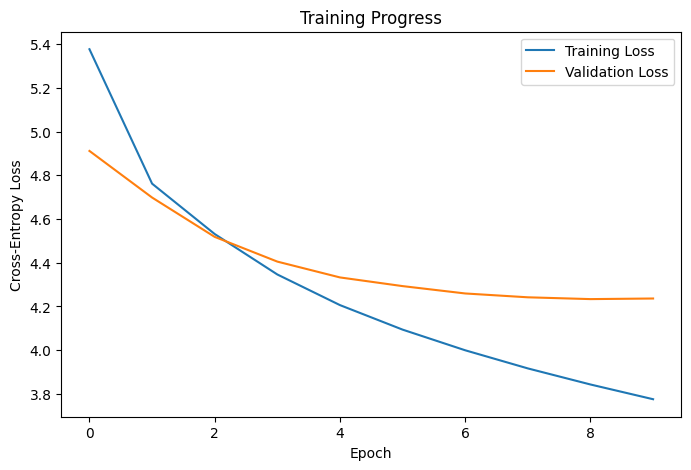

In [135]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Progress")

plt.legend()

plt.show()

In [136]:
test_loss = evaluate(
    model=model2,
    dataloader=test_loader,
    loss_fn=loss_fn,
    device=device
)

print(f"Test Loss: {test_loss:.4f}")

Test Loss: 4.2925


In [138]:
perplexity = math.exp(test_loss)
print(f"Perplexity Reading: {perplexity}")

Perplexity Reading: 73.15012039716972


### Quantitative Results and Experimental Findings

The final model was trained and evaluated using the Cornell Movie-Dialogs Corpus with a custom domain-specific Byte Pair Encoding (BPE) tokenizer containing 16,384 tokens. The resulting decoder-only Transformer contained approximately 14.7 million trainable parameters and was trained using AdamW optimization, mixed precision training (AMP), gradient clipping, and an 80/10/10 train-validation-test split.

##### Baseline Training Configuration

The initial architecture consisted of:

- Context Length: 256
- Embedding Dimension: 256
- Attention Heads: 4
- Transformer Layers: 4
- Feedforward Dimension: 1024
- Dropout: 0.10

A three epoch Initial test was conducted to validate the training pipeline. Training and validation losses decreased consistently, and generated samples demonstrated early acquisition of conversational structure through correct usage of the `<|eou|>` and `<|endofdialog|>` boundary tokens.

##### Experiment 1: Increasing Transformer Depth
**Experiment 1 Not shown In notebook as it was part of a tuning phase and was overwritten in favour of the final model**

The first controlled experiment increased the number of Transformer layers from four to six while keeping all other hyperparameters unchanged.

| Model | Layers | Dropout | Best Validation Loss |
|---------|---------:|---------:|---------:|
| Baseline | 4 | 0.10 | 4.4881 |
| Experiment 1 | 6 | 0.10 | 4.2723 |

The deeper model achieved a lower validation loss and produced noticeably more coherent dialogue samples, supporting the hypothesis that additional model depth improves conversational language modeling performance.

##### Experiment 2: Increased Depth and Regularization

A second experiment increased model depth to eight Transformer layers while simultaneously increasing dropout from 0.10 to 0.20 to reduce overfitting.

| Model | Layers | Dropout | Best Validation Loss |
|---------|---------:|---------:|---------:|
| Baseline | 4 | 0.10 | 4.3881 |
| Experiment 1 | 6 | 0.10 | 4.2723 |
| Experiment 2 | 8 | 0.20 | **4.2336** |

The additional depth further improved validation performance, while the stronger dropout reduced divergence between training and validation losses. This result suggests that increasing model capacity while introducing additional regularization improved generalization on unseen dialogue.

##### Final Model Performance

The final selected model used:

- Vocabulary Size: 16,384
- Context Length: 256
- Embedding Dimension: 256
- Attention Heads: 4
- Transformer Layers: 8
- Feedforward Dimension: 1024
- Dropout: 0.20

Evaluation metrics for the final model were:

| Metric | Value |
|----------|----------:|
| Best Validation Loss | 4.2336 |
| Test Loss | 4.2925 |
| Perplexity | 73.15 |
| Parameters | ~14.7 Million |

The close agreement between validation and test loss indicates that the model generalizes reasonably well to unseen conversations. Furthermore, the consistent improvement observed across both experiments suggests that increased Transformer depth was more beneficial than simply extending training duration, as validation performance plateaued after approximately eight to ten epochs while deeper architectures continued to improve performance.

**Note on Perplexity**

The final model achieved a test-set perplexity of 73.15. Perplexity measures how uncertain a language model is when predicting the next token in a sequence, with lower values indicating more confident and accurate predictions. In practical terms, a perplexity of 73.15 suggests that the model has learned meaningful conversational patterns and dialogue structure but remains uncertain when generating highly diverse movie-dialogue responses.

Because open-ended dialogue generation is inherently more difficult than tasks with constrained outputs, perplexity values should be interpreted relative to comparable dialogue-generation systems rather than as standalone indicators of quality.

### Qualititative Evaluation

In [143]:
# Test 1: Common Conversational Greeting
# prompt="Hello, how are you today? <|eou|>"

output = generate(
    model=model2,
    tokenizer=hf_tokenizer,
    prompt="Hello, how are you today? <|eou|>",
    max_new_tokens=60,
    temperature=0.6,
    device=device
)

print(output)

Hello , how are you today ? <|eou|> Oh , now , well , I don 't know . <|endofdialog|>


**Strengths**

- The model correctly recognized the prompt as conversational dialogue.
- The response is grammatically valid and resembles natural spoken language.
- Dialogue boundary tokens were used correctly, with the conversation terminating using `<|endofdialog|>`.
- The generated reply is plausible for an informal conversation.

**Weaknesses**

- The response is relatively short and provides little elaboration.
- The answer does not directly address the greeting or provide meaningful information about the speaker's state.
- The conversation terminates immediately after a single reply, limiting dialogue depth.

**Assessment**

This example demonstrates that the model has successfully learned basic conversational structure and dialogue formatting. The generated response is coherent and syntactically correct.

While the response is brief, this behavior is consistent with characteristics of the training corpus, where conversations contain a median length of only 28 words and an average length of approximately 42 words. Consequently, the tendency to generate short conversational exchanges may partially reflect patterns learned from the underlying dataset rather than solely representing a model deficiency.

**Overall Rating:** Moderate Quality

In [144]:
# Test 2: Commong Question, more directed and higher difficulty
# prompt="Where have you been? <|eou|>"

output2 = generate(
    model=model2,
    tokenizer=hf_tokenizer,
    prompt="Where have you been? <|eou|>",
    max_new_tokens=60,
    temperature=0.6,
    device=device
)

print(output2)

Where have you been ? <|eou|> And what ? <|eou|> I 'm going to California . I 'm going to get married . <|endofdialog|>


**Strengths**

The model maintained the multi-turn dialogue structure learned from the corpus.
The response remained grammatical and conversational throughout the exchange.
The model correctly used both <|eou|> and <|endofdialog|> markers.
The generated dialogue contains a plausible outcome, where a question is followed by an explanation of future plans.

**Weaknesses**

The response does not directly answer the original question of where the speaker has been.
The intermediate phrase "And what?" introduces an abrupt conversational shift.
Lacks logical consistency.

**Assessment**

This example demonstrates a higher level of conversational capability than the previous greeting example. Rather than producing a single short response, the model generated multiple dialogue turns and introduced a simple narrative involving relocation and marriage. While the logical connection between the prompt and response remains imperfect, the conversation exhibits recognizable human dialogue patterns.

It is also important to consider the characteristics of the training corpus when interpreting this output. Because the model was trained on movie dialogue, generated conversations frequently adopt dramatic, narrative, or emotionally charged directions. Really interesting result here considering the small size of model, this is showing some sofistication.

**Overall Rating**: Good Quality

In [146]:
# Test 3: Considering the dataset (conversational), we can test for emotional intelligence or reasoning
# prompt="I don't know what to do anymore. <|eou|>"

output3 = generate(
    model=model2,
    tokenizer=hf_tokenizer,
    prompt="I don't know what to do anymore. <|eou|>",
    max_new_tokens=60,
    temperature=0.6,
    device=device
)

print(output3)

I don 't know what to do anymore . <|eou|> What 's the problem ? <|eou|> You mean you don 't exactly belong here ? <|eou|> I don 't know ... I mean , I don 't know . I 've been here for years . I mean , I 'm not wanting to think that 's a thing to do with it . <|eou|> I 'm so scared of



**Strengths**

- The model responds appropriately to emotional uncertainty with follow-up questions.
- The conversation develops naturally across multiple dialogue turns.
- The generated dialogue demonstrates emotional awareness through discussion of uncertainty, belonging, and fear.

**Weaknesses**

- Some sentences become difficult to interpret as the conversation progresses.
- The dialogue loses coherence slightly during longer generations.
- The model cannot fully resolve conversations.

**Assessment**

This example demonstrates one of the strongest conversational outputs produced by the model. Rather than generating a short generic reply, the model develops an emotionally focused discussion that includes questioning, self-reflection, and expressions of fear. The output suggests that the model has learned meaningful conversational patterns associated with personal problems and emotional conflict.

**Overall Rating:** Good Quality

In [147]:
# Test 4: Movie type question
# prompt="Do you really think we can pull this off? <|eou|>",

output4 = generate(
    model=model2,
    tokenizer=hf_tokenizer,
    prompt="Do you really think we can pull this off? <|eou|>",
    max_new_tokens=60,
    temperature=0.6,
    device=device
)

print(output4)

Do you really think we can pull this off ? <|eou|> You mean we have to . <|eou|> I don 't know . <|eou|> I 'm not a real deal . <|eou|> Yeah ? <|eou|> I don 't know . <|eou|> You 're a good woman . <|endofdialog|>




**Strengths**

- The model maintains a multi-turn conversational exchange.
- The response contains uncertainty and hesitation, which fits the prompt.
- The dialogue resembles dramatic character interactions commonly found in movie scripts.

**Weaknesses**

- The conversation loses coherence toward the end but still plausible.
- Repetition of "I don't know" suggests limited long-range consistency.

**Assessment**

This example demonstrates the model's ability to sustain multiple conversational turns while maintaining a dramatic tone. Although the dialogue becomes less coherent as it progresses, the overall exchange resembles the style of character-driven movie conversations present in the training corpus.

**Overall Rating:** Good Quality

In [153]:
# Test 5: Out of scope question knowledge question
# prompt="What is the capital of France. <|eou|>"

output5 = generate(
    model=model2,
    tokenizer=hf_tokenizer,
    prompt="What is the capital of France. <|eou|>",
    max_new_tokens=60,
    temperature=0.6,
    device=device
)

print(output5)

What is the capital of France . <|eou|> That 's enough , but I 've never had a few days . <|eou|> We 'll see you . <|eou|> I 'm not going to . <|eou|> Why ? <|eou|> I don 't know . <|endofdialog|>


**Strengths**

- The dialogue remains grammatically valid throughout.
- Conversation boundary tokens are used well but not perfectly.

**Weaknesses**

- The model fails to answer the factual question.
- The generated responses quickly drift away from the original topic.
- No evidence of factual knowledge about France or its capital is demonstrated.

**Assessment**

This example highlights a key limitation of the model. Although it successfully generates dialogue in the style of a conversation, it cannot provide factual answers outside the scope of its training data. Because the model was trained exclusively on movie dialogue rather than factual reference material, it prioritizes generating plausible conversational responses over retrieving correct information. This demonstrates that the model learned dialogue patterns rather than general world knowledge.

**Overall Rating:** Failure Case

### Notebook Summary

This project investigated whether a custom tokenized decoder-only Transformer could learn meaningful conversational patterns from the Cornell Movie-Dialogs Corpus while remaining computationally efficient on modest GPU hardware. A custom Byte Pair Encoding (BPE) tokenizer reduced the vocabulary size from 50,257 to 16,384 tokens, improving vocabulary utilization and reducing embedding overhead, which enabled deeper Transformer architectures to be trained within Google Colab resource constraints. Key training challenges included working with a relatively narrow movie-dialogue corpus and balancing model capacity against limited GPU memory and training time. These challenges were addressed through data centric design choices, mixed precision training (AMP), gradient clipping, and iterative architecture experiments.

Qualitative evaluation showed that the final model successfully learned conversational turn-taking, dialogue boundaries, emotional exchanges, and movie-style interactions. Experimental results demonstrated that increasing model depth and dropout improved validation performance from 4.4881 in the baseline model to 4.2336 in the final model while reducing overfitting. Although the model occasionally produced repetitive responses, lost coherence during longer generations, and struggled with factual question-answering outside the scope of movie dialogue, the results suggest that a custom-tokenized GPT-style architecture can generate coherent and contextually appropriate dialogue while remaining computationally practical on modest hardware.

